### Lab 6: Part 2
#### Name: Anna Phillips

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('./data/diabetes.csv', index_col = 0)

df.head()

,treatment,outcome
1,met,success
2,rosi,failure
3,rosi,success
4,lifestyle,success
5,met,success


#### **1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups?**

In [3]:
## Crosstabs, average treatment effect:
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

df["outcome"] = df["outcome"].map({
    "success": 1,
    "failure": 0
})

print(f'Lifestyle mean: {df.loc[df['treatment'] == 'lifestyle', 'outcome'].mean():.3f}')
print(f'Rosi mean: {df.loc[df['treatment'] == 'rosi', 'outcome'].mean():.3f}')
print(f'Met mean: {df.loc[df['treatment'] == 'met', 'outcome'].mean():.3f}')
print()

ate1 = df.loc[ df['treatment'] == 'lifestyle', 'outcome'].mean() \
    - df.loc[ df['treatment'] == 'met', 'outcome'].mean() 

ate2 = df.loc[ df['treatment'] == 'lifestyle', 'outcome'].mean() \
    - df.loc[ df['treatment'] == 'rosi', 'outcome'].mean() 

ate3 = df.loc[ df['treatment'] == 'rosi', 'outcome'].mean() \
    - df.loc[ df['treatment'] == 'met', 'outcome'].mean() 

print('Estimated ATE (lifestyle - met): ', np.round(ate1, 3))
print('Estimated ATE (lifestyle - rosi): ', np.round(ate2, 3))
print('Estimated ATE (rosi - met): ', np.round(ate3, 3))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Lifestyle mean: 0.534
Rosi mean: 0.614
Met mean: 0.483

Estimated ATE (lifestyle - met):  0.051
Estimated ATE (lifestyle - rosi):  -0.08
Estimated ATE (rosi - met):  0.131


***Answer (1):*** Across the three groups, lifestyle succeeds 53.4% of the time, met succeeds 48.3% of the time, and rosi succeeds 61.4% of the time.

#### **2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms.** 


In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['treatment'] == 'lifestyle',:]
df_b = df.loc[ df['treatment'] == 'rosi',:]
df_c = df.loc[ df['treatment'] == 'met',:]

outcome_a = []
outcome_b = []
outcome_c = []
ate_ab = [] # Store computed effects
ate_ac = [] # Store computed effects
ate_bc = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)
    df_ct = df_c.sample(frac=1.0, replace=True)


    ## Evaluate outcomes:
    oat = df_at['outcome'].mean() # Mean outcome for A
    obt = df_bt['outcome'].mean() # Mean outcome for B   
    oct = df_ct['outcome'].mean() # Mean outcome for B   

    ## Compute ATE:
    ate_1 = oat - obt # Compute ATE for this bootstrap sample
    ate_2 = oat - oct # Compute ATE for this bootstrap sample
    ate_3 = obt - oct # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    outcome_c.append(oct) # Save new value
    ate_ab.append(ate_1) # Save new value
    ate_ac.append(ate_2) # Save new value
    ate_bc.append(ate_3) # Save new value

#### **3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.**

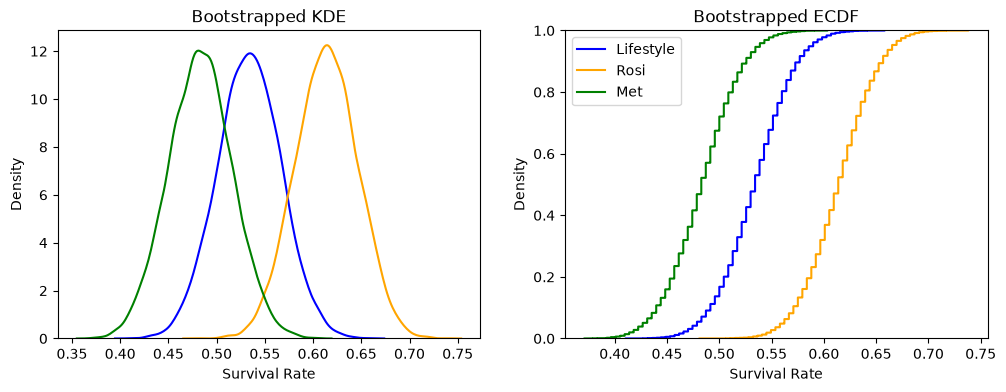

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Rosi', color='orange', ax=ax[0])
sns.kdeplot(outcome_c, label='Met', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Rosi', color='orange', ax=ax[1])
sns.ecdfplot(outcome_c, label='Met', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

***Answer (3):*** 

#### **4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.**


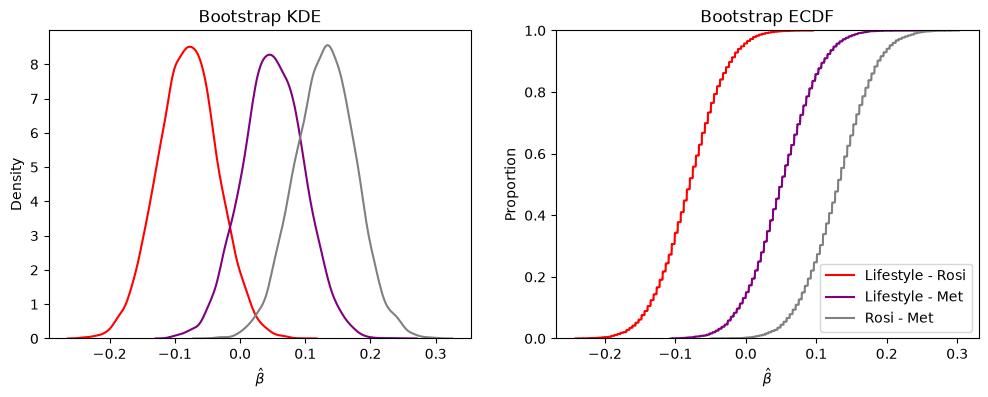

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_ab, label = "Lifestyle - Rosi", color = "red", ax=ax[0])
sns.kdeplot(ate_ac, label = "Lifestyle - Met", color = "purple", ax=ax[0])
sns.kdeplot(ate_bc, label = "Rosi - Met", color = "grey", ax=ax[0])

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate_ab, label = "Lifestyle - Rosi", color = "red", ax=ax[1])
sns.ecdfplot(ate_ac, label = "Lifestyle - Met", color = "purple", ax=ax[1])
sns.ecdfplot(ate_bc, label = "Rosi - Met", color = "grey", ax=ax[1])

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.legend()
plt.show()

#### **5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?**

In [7]:
ci90 = np.quantile(ate_ab, [.05, .95])
ci95 = np.quantile(ate_ab, [.025, .975])
ci99 = np.quantile(ate_ab, [.005, .995])

print("Lifestyle - Rosi")
print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")
print()

ci90 = np.quantile(ate_ac, [.05, .95])
ci95 = np.quantile(ate_ac, [.025, .975])
ci99 = np.quantile(ate_ac, [.005, .995])

print("Lifestyle - Met")
print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")
print()

ci90 = np.quantile(ate_bc, [.05, .95])
ci95 = np.quantile(ate_bc, [.025, .975])
ci99 = np.quantile(ate_bc, [.005, .995])

print("Rosi - Met")
print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

Lifestyle - Rosi
90% CI: [-0.15650563 -0.00260354]
95% CI: [-0.16945453  0.01036325]
99% CI: [-0.19511408  0.04020405]

Lifestyle - Met
90% CI: [-0.02582523  0.12857353]
95% CI: [-0.0426982   0.14176245]
99% CI: [-0.07309166  0.1715298 ]

Rosi - Met
90% CI: [0.05357407 0.20419565]
95% CI: [0.04056858 0.22130753]
99% CI: [0.01052612 0.25133195]


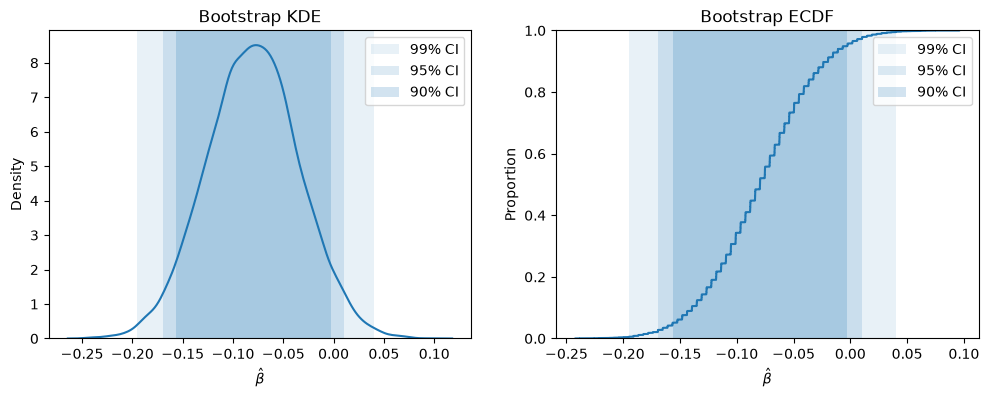

In [8]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate_ab, [.05, .95])
ci95 = np.quantile(ate_ab, [.025, .975])
ci99 = np.quantile(ate_ab, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_ab, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate_ab, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

plt.show()

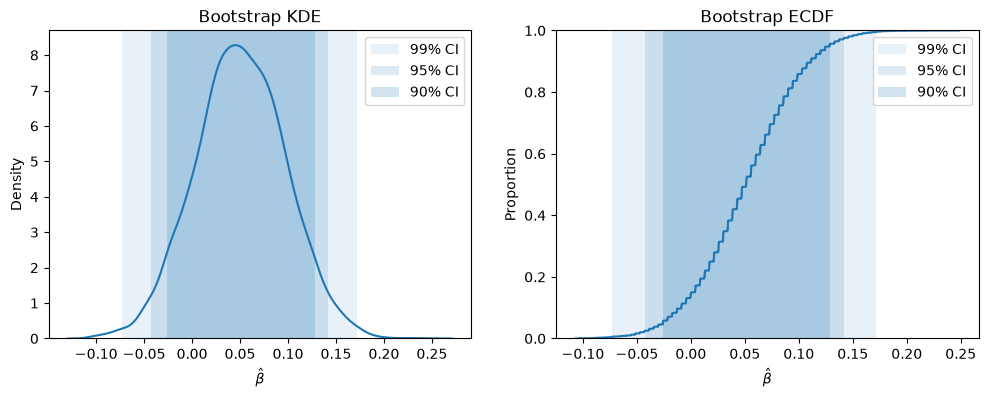

In [9]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate_ac, [.05, .95])
ci95 = np.quantile(ate_ac, [.025, .975])
ci99 = np.quantile(ate_ac, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_ac, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate_ac, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

plt.show()

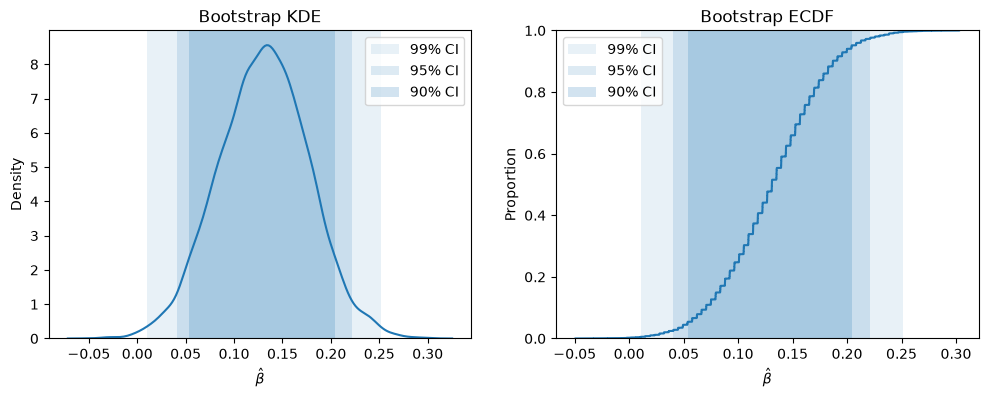

In [10]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate_bc, [.05, .95])
ci95 = np.quantile(ate_bc, [.025, .975])
ci99 = np.quantile(ate_bc, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_bc, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()


## ECDF
sns.ecdfplot(ate_bc, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

plt.show()

***Answer (5):*** 

#### **6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.**